In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [8]:
rho = torch.tensor([float(x) for x in "1	1.07226722201032	1.14975699539774	1.23284673944207	1.32194114846603	1.41747416292681	1.51991108295293	1.62975083462064	1.74752840000768	1.87381742286038	2.00923300256505	2.15443469003188	2.31012970008316	2.47707635599171	2.65608778294669	2.84803586843580	3.05385550883342	3.27454916287773	3.51119173421513	3.76493580679247	4.03701725859655	4.32876128108306	4.64158883361278	4.97702356433211	5.33669923120631	5.72236765935022	6.13590727341317	6.57933224657568	7.05480231071864	7.56463327554629	8.11130830789687	8.69749002617784	9.32603346883220	10	10.7226722201032	11.4975699539774	12.3284673944207	13.2194114846603	14.1747416292681	15.1991108295293	16.2975083462064	17.4752840000768	18.7381742286038	20.0923300256505	21.5443469003188	23.1012970008316	24.7707635599171	26.5608778294669	28.4803586843580	30.5385550883342	32.7454916287773	35.1119173421513	37.6493580679247	40.3701725859655	43.2876128108306	46.4158883361278	49.7702356433211	53.3669923120631	57.2236765935022	61.3590727341317	65.7933224657568	70.5480231071864	75.6463327554629	81.1130830789687	86.9749002617783	93.2603346883220	100	107.226722201032	114.975699539774	123.284673944207	132.194114846603	141.747416292680	151.991108295293	162.975083462064	174.752840000768	187.381742286039	200.923300256505	215.443469003188	231.012970008316	247.707635599171	265.608778294669	284.803586843580	305.385550883342	327.454916287773	351.119173421513	376.493580679247	403.701725859655	432.876128108306	464.158883361278	497.702356433211	533.669923120631	572.236765935022	613.590727341318	657.933224657568	705.480231071865	756.463327554629	811.130830789687	869.749002617783	932.603346883220	1000".split()])

In [298]:
t_gates = lambda x: torch.tensor([2.1900e-06, 5.1900e-06, 7.1900e-06, 9.1900e-06, 1.1190e-05, 1.3190e-05,
        1.5190e-05, 1.7190e-05, 1.9190e-05, 2.1190e-05, 2.3690e-05, 2.6690e-05,
        3.0190e-05, 3.4690e-05, 4.0690e-05, 4.8190e-05, 5.7190e-05, 6.8690e-05,
        8.3190e-05, 1.0170e-04, 1.2520e-04, 1.5420e-04, 1.9120e-04, 2.3770e-04,
        2.9570e-04, 3.6920e-04, 4.6170e-04, 5.7820e-04, 7.2470e-04, 9.0920e-04])
radius = 1.#/np.sqrt(np.pi)
times=t_gates(None)

In [299]:
import math
sqrt_pi = float(np.pi**0.5)
mu0 = float(np.pi*4e-7)

def analytic(times, rhos, r, I=1.):
    dbdt = np.empty(rhos.shape+times.shape)
    for i_rho, rho in enumerate(rhos):
        sigma = 1./rho
        for i_t,time in enumerate(times):    
            sigma = 1./rho
            theta = math.sqrt(0.25*mu0*sigma / time)
            dhdt = 1./(mu0*sigma*r**3)*(3*math.erf(theta*r)-2*theta*r*(3+2*theta**2*r**2)*math.exp(-theta**2*r**2)/sqrt_pi)
            dbdt[i_rho, i_t] = dhdt
    return dbdt*mu0

dbdt_analytic = analytic(times.numpy(), rho.numpy(), radius).real

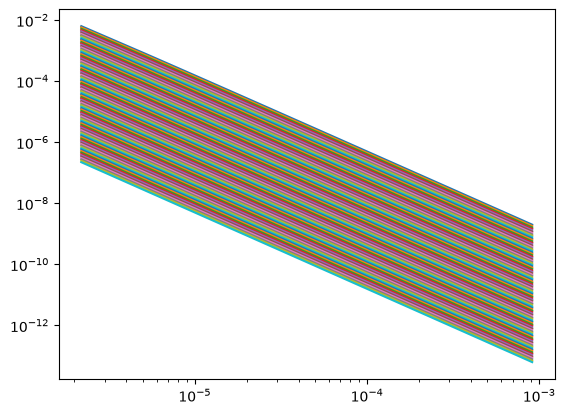

In [300]:
plt.figure()
plt.loglog(times.numpy(), dbdt_analytic.T);

In [301]:
from anemone.system import *
tx = Loop.circle(radius)
rx = Receiver()

In [409]:
from anemone.forwards import *
from anemone.transforms import hankel_coefficients, Fourier
from anemone.physics import rte_halfspace

class Hankel2(Hankel):
    def __init__(self, func, order, log10min=-20, log10max=20, smp_per_decade=10, range=None, tolerance=None, lambda_included=True, omega_0=np.pi/4., a=0.1):
        self.func    = func
        self.nu    = order
        self.smp_per_decade = smp_per_decade
        self.n_decades = log10max-log10min
        hkl = hankel_coefficients(order, log10min, log10max, smp_per_decade, omega_0, a=a)
        self.tolerance = tolerance

        self.func_results = None       

        self.lamda = torch.clone(hkl[0])#.to(rdtype())
        self.fc = torch.clone(hkl[1])#.to(rdtype())

        
        self.lambda_included = lambda_included

        self.rc = 1.
        self.rcidx = 0
        if range is not None:
            self._recenter_function(range)
            self.create_interpolator(range[0], range[1])

    def _recenter_function(self, r_center):
        assert self.rcidx == 0, "recentering is only allowed once"
        if isinstance(r_center, tuple): r_center = torch.sqrt(r_center[0]*r_center[1]).to(self.device)
        self.rc = r_center#.to(rdtype())
        self.lamda = self.lamda/self.rc
        self.rcidx = self.smp_per_decade*torch.log10(self.rc)
        self.func_results = None

    def create_interpolator(self, rmin, rmax):
        if self.func_results is None:
            self.func_results = self.func(self.lamda)
            if not self.lambda_included:
                self.func_results *= self.lamda
        self.r, self.resp = self.range(rmin, rmax)
        self.interpfunc = CubicSpline(self.r, self.resp, transform=torch.log10, integrate=False)
    
    
    def r_to_idx(self, r):
        return self.smp_per_decade*torch.log10(r)-self.rcidx
    
    def idx_to_r(self, idx):
        return 10**((idx + self.rcidx)*self.delta)
    

    @property
    def delta(self):
        """
        Calculate the delta value.

        Returns:
        - delta (float): The delta value.

        """
        return 1. / self.smp_per_decade

    
    def range(self, rmin, rmax):
        """ the reason for this is to make it reusable for the fourier transform"""
        return self._range(rmin, rmax)

    def _range(self, rmin, rmax):
        """
        Compute the range of values between `rmin` and `rmax`.

        Parameters:
        - rmin (float): The minimum value of the range.
        - rmax (float): The maximum value of the range.

        Returns:
        - rout (torch.Tensor): The range of values between `rmin` and `rmax`.
        - HR (torch.Tensor): The computed values based on the range.

        """
        if self.func_results is None:
            self.func_results = self.func(self.lamda)
            if not self.lambda_included: 
                self.func_results *= self.lamda
        if not isinstance(rmin, torch.Tensor): rmin = torch.tensor(rmin)
        if not isinstance(rmax, torch.Tensor): rmax = torch.tensor(rmax)
        imin = int(torch.floor(self.r_to_idx(rmin)))-2
        imax = int(torch.ceil(self.r_to_idx(rmax)))+2
        i_offsets = torch.arange(imin, imax)
        rout = self.idx_to_r(i_offsets).to(self.lamda.dtype)
        HR = torch.zeros(self.func_results.shape[:-1] + rout.shape, dtype=self.func_results.dtype)

        if self.fc.dtype != self.func_results.dtype:
            self.fc = self.fc.to(self.func_results.dtype)   

         


        for i, i_offset in enumerate(i_offsets):
            if i_offset == 0:
                HR[..., i] = torch.einsum('...i,...i->...', self.func_results, self.fc)
            elif i_offset > 0:
                HR[..., i] = torch.einsum('...i,...i->...', self.func_results[..., :-i_offset], self.fc[..., i_offset:])
            else:
                i_offset *= -1
                HR[..., i] = torch.einsum('...i,...i->...', self.fc[..., :-i_offset], self.func_results[..., i_offset:])
        
        return rout, HR/rout
        
    def __call__(self, r):
        if isinstance(r, float): r = torch.tensor(r)
        rmax = r.max()
        rmin = r.min()
        if not 'interpfunc' in dir(self):
            self.r, self.resp = self.range(rmin, rmax)
            self.interpfunc = CubicSpline(self.r, self.resp, transform=torch.log10)
        r = r if isinstance(r, torch.Tensor) else torch.tensor(r)
        return self.interpfunc(r)#.to(self.device)
    
    def preintegrate(self, GeomOperator, rmin, rmax):
        if self.func_results is None:
            self.func_results = self.func(self.lamda)
            if not self.lambda_included: 
                self.func_results *= self.lamda
        if not isinstance(rmin, torch.Tensor): rmin = torch.tensor(rmin)
        if not isinstance(rmax, torch.Tensor): rmax = torch.tensor(rmax)
        imin = int(torch.floor(self.r_to_idx(rmin)))-2
        imax = int(torch.ceil(self.r_to_idx(rmax)))+2
        i_offsets = torch.arange(imin, imax)
        rout = self.idx_to_r(i_offsets).to(self.lamda.dtype)
        geomz = GeomOperator(rout).squeeze()



        FC = torch.zeros(geomz.shape[:-1]+self.fc.shape)
        
        while self.fc.ndim < FC.ndim:
            self.fc = self.fc[None, :]
        
        for i, i_offset in enumerate(i_offsets):
            if i_offset == 0:
                FC += geomz[..., i, None]*self.fc / rout[i]
            elif i_offset > 0:
                FC[..., :-i_offset] += geomz[..., i, None]*self.fc[..., i_offset:] / rout[i]
            else:
                i_offset *= -1
                FC[..., i_offset:] += geomz[..., i, None]*self.fc[..., :-i_offset] / rout[i]
        
        if self.tolerance is not None:
            idxmin, idxmax = coefficient_bounds(FC.cpu().numpy(), tolerance=self.tolerance)
            idx_slice = slice(idxmin, idxmax)
        else:
            idx_slice = slice(None, None)
        if FC.dtype != self.func_results.dtype:
            FC = FC.to(self.func_results.dtype)   
        return torch.einsum('ji,...i->j...', self.func_results, FC), FC[idx_slice], self.lamda[..., idx_slice]


class Fourier2(Hankel2):
    def __init__(self, func, log10min=-20, log10max=20, smp_per_decade=16, range=None, tolerance=None, r_omega0=np.pi/5.25, i_omega0=np.pi/5.25, r_a=0.1, i_a=0.1):
        def f1(lamda):
            x = func(lamda/c.sqrt_twopi)
            return x.permute(*torch.arange(x.ndim - 1, -1, -1))/torch.sqrt(lamda)
        super().__init__(f1, -0.5, log10min, log10max, smp_per_decade,  None)
        self.lambda_included = False
        _, realfc = hankel_coefficients(-0.5, log10min, log10max, smp_per_decade, omega_0=r_omega0, a=r_a)
        _, imagfc = hankel_coefficients( 0.5, log10min, log10max, smp_per_decade, omega_0=i_omega0, a=i_a)
        self.fc = torch.complex(realfc, -1*imagfc)
        self.f1 = f1
       

        if range is not None:
            self._recenter_function(range)
            self.create_interpolator(range[0], range[1])

    def f2r(self, f):
        """frequency to r"""
        return f*c.sqrt_twopi
    def r2f(self, r):
        """r to frequency"""
        return r/c.sqrt_twopi

    def range(self, fmin, fmax):
        rout, Resp = self._range(self.f2r(fmin), self.f2r(fmax))
        return self.r2f(rout), Resp*torch.sqrt(rout)
    
    def __call__(self, r):
        if isinstance(r, float): r = torch.tensor(r)
        rmax = r.max()
        rmin = r.min()
        if not 'interpfunc' in dir(self):
            self.r, self.resp = self.range(rmin, rmax)
            self.interpfunc = CubicSpline(self.r, self.resp, integrate=False, transform=torch.log10)
        r = r if isinstance(r, torch.Tensor) else torch.tensor(r)
        return self.interpfunc(r)


    def calc_tvals(self, tmin, tmax):
        rmin,rmax = self.f2r(tmin), self.f2r(tmax)
        if not isinstance(rmin, torch.Tensor): rmin = torch.tensor(rmin)
        if not isinstance(rmax, torch.Tensor): rmax = torch.tensor(rmax)
        imin = int(torch.floor(self.r_to_idx(rmin)))-2
        imax = int(torch.ceil( self.r_to_idx(rmax)))+2
        i_offsets = torch.arange(imin, imax)
        rout = self.idx_to_r(i_offsets).to(self.lamda.dtype)
        return i_offsets, rout, self.r2f(rout)

    def preintegrate(self, timeOperator, tmin, tmax):
        i_offsets, rout, tout = self.calc_tvals(tmin, tmax)
        Wmat = timeOperator(tout).to(cdtype())

        if self.func_results is None:
            self.func_results = self.func(self.lamda)
            if not self.lambda_included: 
                self.func_results *= self.lamda


        if self.fc.dtype != self.func_results.dtype:
            self.fc = self.fc.to(self.func_results.dtype)   

        FC = torch.zeros(Wmat.shape[:-1]+self.fc.shape, dtype=cdtype())
        sqRout = torch.sqrt(rout)
        
        for i, i_offset in enumerate(i_offsets):
            if i_offset == 0:
                FC += Wmat[..., i, None]*self.fc*sqRout[i]/rout[i]
            elif i_offset > 0:
                FC[..., :-i_offset] += Wmat[..., i, None]*self.fc[i_offset:]*sqRout[i]/rout[i]
            else:
                i_offset *= -1
                FC[..., i_offset:] += Wmat[..., i, None]*self.fc[:-i_offset]*sqRout[i]/rout[i]
        
        if FC.dtype != self.func_results.dtype:
            FC = FC.to(self.func_results.dtype)   
                    
        if self.tolerance is not None:
            idxmin, idxmax = FC.shape[-1]-1, 0
            for i in range(len(FC)):
                cimin,cimax = coefficient_bounds(FC[i].cpu().numpy(), tolerance=self.tolerance)
                idxmin = min(idxmin, cimin)
                idxmax = max(idxmax, cimax)

            return torch.einsum('ij,...j->...i', FC, self.func_results), FC[..., idxmin:idxmax], self.lamda.squeeze()[idxmin:idxmax]
        else:
            return torch.einsum('ij,...j->...i', FC, self.func_results), FC, self.lamda.squeeze()


class invFourier2(Fourier2):
    def __init__(self, func, log10min=-20, log10max=20, smp_per_decade=16, range=None, tolerance=None, r_omega0=np.pi/5.25, i_omega0=np.pi/5.25, r_a=0.1, i_a=0.1):
        super().__init__(func, log10min, log10max, smp_per_decade, None, r_omega0=r_omega0, i_omega0=i_omega0, r_a=r_a, i_a=i_a)
        self.lambda_included = False        
        self.fc = self.fc.real - 1j*self.fc.imag
        self.tolerance = tolerance
        if range is not None:
            self._recenter_function(range)
            self.create_interpolator(range[0], range[1])

def make_forward(x, smoothing=False):
    tolerance              = x[0]
    hankel_smp_per_decade  = x[1]
    fourier_smp_per_decade = x[2]

    hankel_omega0          = x[3]
    hankel_a               = x[4]

    fourier_r_omega0 = x[5]
    fourier_i_omega0 = x[6]
    fourier_r_a      = x[7]
    fourier_i_a      = x[8]
    bias_factor      = 1.#x[9]

    class Forward2(BaseForward):
        def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_end=None, tolerance=tolerance, do_setup=True, **kwargs):
            
            super().__init__(source, receiver, times, waveform, filterfunc, t_end, tolerance, **kwargs)
            self.t2t = kwargs.get('t2t', None)
            self.H2t = kwargs.get('H2t', None)
            self.omega = kwargs.get('omega', None)
            self.lamda = kwargs.get('lamda', None)

            if self.H2t is None and do_setup: 
                self.setup()
                self.omega = self.omega.to(cdtype())
                self.lamda = self.lamda.to(cdtype())

        def setup(self):
            self.rho   = 40*torch.ones(2, dtype=cdtype())[:, None, None]
            self.thick = 20*torch.ones(1, dtype=cdtype())[:, None, None]
            with torch.no_grad():
                self.rho   = 40*torch.ones(2, dtype=cdtype())[:, None, None]
                self.thick = 20*torch.ones(1, dtype=cdtype())[:, None, None]

                def frq_integrand(f):
                    self.omega = c.twopi*f[None,:,None]
                    def wvlngth_integrand(wave_length):
                        """ Hz from horizontal electric dipole. """
                        self.lamda = wave_length[None, None, :]          
                        self.sfield_rte = torch.exp(-self.lamda*self.sfield_dz)*self.lamda / c.fourpi
                        intg = rte(1./self.rho, self.thick, self.omega, self.lamda)*self.sfield_rte
                        return intg.squeeze()
                    hkl1 = Hankel2(wvlngth_integrand, 1, smp_per_decade=hankel_smp_per_decade, omega_0=hankel_omega0, a=hankel_a)
                    def geomz_r(r):
                        return self.source.geomz(self.receiver, r).to(rdtype())
                    Hr, self.geomz, self.lamda1 = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
                    
                    self.geomz *= torch.exp(-self.lamda1*self.sfield_dz)*self.lamda1 / c.fourpi
                    return Hr.squeeze()
                

                self.cbft=invFourier2(frq_integrand,  smp_per_decade=fourier_smp_per_decade, r_omega0=fourier_r_omega0, i_omega0=fourier_i_omega0, r_a=fourier_r_a, i_a=fourier_i_a)
                def t2t_func(t_in):
                    if self.t_end is not None:
                        wv_mat = waveform_matrix(t_in, t_in, waveform=self.waveform)
                        self.gate_mat = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                        
                        return self.gate_mat @ wv_mat
                    else:
                        self.gate_mat = None
                        return waveform_matrix(self.times, t_in, waveform=self.waveform)

                
                Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)



                if self.filterfunc is not None:
                    self.t2t *= self.filterfunc.omega_filter(self.omega1*c.sqrt_twopi)#.squeeze()
                if self.waveform is not None:
                    self.t2t /= -1j*c.sqrt_twopi
                else:
                    self.t2t *= self.omega1.squeeze()
                self.t2t /= torch.sqrt(self.omega1.squeeze())
                self.H2t, self.omega, self.lamda = make_H2t(self.t2t, self.geomz.real, self.omega1.real, self.lamda1.real, tolerance=self.tolerance)
                self.H2t *= c.mu0
                self.omega *= c.sqrt_twopi
                self.rho    = None
                self.thick  = None

        def halfspace(self, rho):
            cRTE = rte_halfspace(1./rho[:, None], self.omega[None,:], self.lamda[None,:])
            return torch.einsum('ij,kj->ik',cRTE ,  self.H2t).real.numpy()
    if smoothing:
        t_grid = torch.logspace(-7, -2, 301)
        fwr = Forward2(tx, rx, t_grid)
        times = t_gates(None)


        H2t = fwr.H2t.numpy().T
        t = fwr.times.numpy()
        H2t *= t**(5/2)

        for _ in range(6):
            avgMat = np.zeros((len(t_grid), len(t_grid)))
            footprint = 11
            for i,ct in enumerate(t_grid.numpy()):
                i_t = np.searchsorted(t, ct)-1
                t_slice = slice(max(0, i_t-footprint), min(i_t+footprint, len(t_grid)))
                avgMat[i, t_slice] = 1.
            avgMat /= avgMat.sum(-1, keepdims=True)
            
            H2t = (avgMat @ H2t.T).T
            # H2t *= 1.01

        avgMat = np.zeros((len(times), len(t_grid)))
        footprint = 1
        for i,ct in enumerate(times.numpy()):
            i_t = np.searchsorted(t, ct)-1
            # t_slice = slice(max(0, i_t-footprint), min(i_t+footprint, len(t_grid)))
            avgMat[i, i_t] = 1.
        avgMat /= avgMat.sum(-1, keepdims=True)
        
        H2t = (avgMat @ H2t.T).T

        H2t *= times.numpy()**(-5/2)
        fwr.H2t = torch.from_numpy(H2t).T
        fwr.H2t *= bias_factor
        return fwr
    else:
        times = t_gates(None)
        
        fwr = Forward2(tx, rx, times)
        fwr.H2t *= bias_factor
        return fwr

In [410]:
fwr0 = make_forward([1e-6, 10, 16, np.pi/4., 0.1, np.pi/5.25, np.pi/5.25, 0.1, 0.1, 1.0], smoothing=False)

In [397]:
tolerance=None

h_spd=4
f_spd=6

def objective_function(x):
    cfwr = make_forward([tolerance, h_spd, f_spd]+x.tolist(), smoothing=False)
    dbdt_anemone = cfwr.halfspace(rho)
    relerr =   100*(dbdt_anemone - dbdt_analytic) / np.abs(dbdt_analytic)
    return relerr.flatten()

In [382]:
from scipy.optimize import least_squares

In [398]:
res = least_squares(objective_function, np.array([np.pi/4., 0.1, np.pi/5.25, np.pi/5.25, 0.1, 0.1]), method='lm')

In [419]:
fwr0 = make_forward([1e-6, 10, 16, np.pi/4., 0.1, np.pi/5.25, np.pi/5.25, 0.1, 0.1, 1.], smoothing=False)

print(res.x)
cfwr = make_forward([1e-4, h_spd, f_spd]+res.x.tolist(), smoothing=True)
cfwr.H2t *= 1.01

[0.78539816 0.59563586 0.5983986  0.5983986  0.17572803 0.16374982]


number of terms:  torch.Size([1115])
number of terms:  torch.Size([9713])


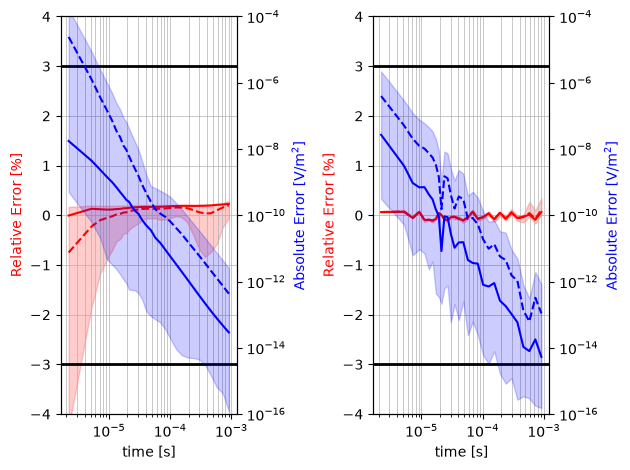

In [420]:
fig,axs = plt.subplots(1,2)

for ax,fwr in zip(axs, [cfwr, fwr0]):
    print('number of terms: ', fwr.omega.shape)
    dbdt_anemone = fwr.halfspace(rho)
    relerr =   100*(dbdt_anemone - dbdt_analytic) / np.abs(dbdt_analytic)
    abserr   = np.abs(dbdt_anemone - dbdt_analytic)
    c1 = "#FF0000"
    c2 = "#0000FF"

    ax2 = ax.twinx()

    ax.semilogx(times, relerr.mean(0), '--', color=c1)
    ax.semilogx(times, np.median(relerr, axis=0), '-', color=c1)
    lb = np.percentile(relerr, 5, axis=0)
    ub = np.percentile(relerr, 95, axis=0)
    ax.fill_between(times, lb, ub, color=c1, alpha=0.2)

    ax2.loglog(times, abserr.mean(0), '--', color=c2)
    ax2.loglog(times, np.median(abserr, axis=0), '-', color=c2)
    lb = np.percentile(abserr, 5, axis=0)
    ub = np.percentile(abserr, 95, axis=0)
    ax2.fill_between(times, lb, ub, color=c2, alpha=0.2)

    ax2.set_ylabel('Absolute Error [V/m$^2$]', color=c2)
    ax.set_ylabel('Relative Error [%]', color=c1)

    ax.set_ylim(-4,4)
    ax2.set_ylim(1e-16, 1e-4)
    ax.grid(lw=0.5, which='both')
    # ax.set_title('anemone / analytic')
    ax.axhline(3, color='k', lw=2)
    ax.axhline(-3, color='k', lw=2)
    ax.set_xlabel('time [s]')
plt.tight_layout()